# AP02 Spick UNBEDINGT SCHAUEN DASS ALLE METHODEN AUS FOLIEN V4 DRIN SIND!
## V4 Ü1: Apartment Data

## Libraries & Settings

In [18]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02


## Importing Data

In [19]:
#Falls du Dateien nicht findest (Speicherorte), diesen Code ausführen und den Output anschauen!
import os                               #Zugriff auf Ordnerinformationen
print("Arbeitsordner:", os.getcwd())    #Ordner anzeigen, von dem der relative Dateipfad ausgeht
print("Dateien:", os.listdir())         #Dateinamen im Arbeitsordner anzeigen

Arbeitsordner: /workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02
Dateien: ['apartments_data_zuerich.csv', 'apartments_data_geocoded.csv', 'Aufgaben Zusatz V4-5 Lösung.ipynb', 'Aufgaben V4 Ü3.1 Lösung.ipynb', 'reviews.json', 'Aufgaben Zusatz V4-5.ipynb', 'Aufgaben V4 Ü3.1.ipynb', 'Aufgaben V4 Ü3.2 Lösung.ipynb', 'Aufgaben V4 Ü3.2.ipynb', 'AP02 Spick.ipynb', 'autoscout24_data.csv', 'autoscout24_data_geocoded.csv', 'smartphones_clean.csv', 'smartphone_data.xlsx', 'html']


In [20]:
#Dateien einlesen: apartments data
# Read the data to a pandas data frame
df_apartments = pd.read_csv('./apartments_data_zuerich.csv',        #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=',',                                           #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                  #Datei mit UTF-8-Zeichenkodierung lesen

# Show first records of data frame
df_apartments.head()                                                #Erste fünf Zeilen der Tabelle anzeigen

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86..."
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,..."
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri..."
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,..."
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8..."


In [21]:
#Dateien einlesen: car data
# Import data from csv to pandas dataframe named 'df'
df_autoscout = pd.read_csv('./autoscout24_data.csv',                #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=";",                                           #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                  #Datei mit UTF-8-Zeichenkodierung lesen

# Change the column names to lowercase
df_autoscout.columns = df_autoscout.columns.str.lower()                 #Alle Spaltennamen in Kleinbuchstaben umwandeln

# Display the first 5 rows of the dataframe
df_autoscout.head()                                                 #Erste fünf Zeilen der Tabelle anzeigen

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


In [22]:
#Dateien einlesen: smartphone data
# Import data from csv to pandas dataframe named 'df_clean'
df_smartphone = pd.read_csv('smartphones_clean.csv')         #CSV aus dem Arbeitsordner einlesen und als df_clean speichern

# Show dimensions and first rows
print('Number of rows and columns:', df_smartphone.shape)    #Anzahl Zeilen und Spalten als (Zeilen, Spalten) anzeigen
df_smartphone.head()                                         #Erste fünf Zeilen der Tabelle anzeigen

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


### Anzahl Zeilen und Spalten einer Tabelle anzeigen

Zeigt, wie viele Datensätze und Merkmale die Tabelle enthält
- Zeilen = Datensätze, bspw. einzelne Velos
- Spalten = Merkmale, bspw. Marke, Modell und Preis
- df.shape liefert beide Anzahlen als (Zeilen, Spalten)
- df.shape[0] liefert nur die Zeilenanzahl
- df.shape[1] liefert nur die Spaltenanzahl
NICHTS ANPASSEN: wenn deine bereits eingelesene Tabelle df heisst

In [23]:
print("Dimension:", df_apartments.shape)           #Anzahl Zeilen und Spalten als (Zeilen, Spalten)
print("Anzahl Zeilen:", df_apartments.shape[0])    #Anzahl Datensätze anzeigen
print("Anzahl Spalten:", df_apartments.shape[1])   #Anzahl Merkmale anzeigen

#NICHTS ANPASSEN: wenn deine Tabelle df heisst
#0 und 1 bleiben gleich: Sie wählen die Zeilenanzahl bzw. Spaltenanzahl aus
#Gezählt werden alle vorhandenen Zeilen und Spalten, auch bei fehlenden Werten oder Duplikaten

Dimension: (1008, 7)
Anzahl Zeilen: 1008
Anzahl Spalten: 7


### Vorhandene Spaltennamen anzeigen

Zeigt die exakten Namen aller Spalten einer Tabelle als Liste an; damit kannst du prüfen, welche Spalten vorhanden sind und wie sie geschrieben werden

Gross-/Kleinschreibung beachten: `Price_Raw`, `price_raw` und `price` sind unterschiedliche Spaltennamen
Ein `KeyError` kann bedeuten, dass die angegebene Spalte fehlt oder anders geschrieben ist

ANPASSEN: `df_autoscout` an den Namen deiner Tabelle

In [24]:
print(df_autoscout.columns.tolist()) #Vorhandene Spalten von df_autoscout anzeigen

display(df_autoscout) #Gesamten Dataframe anzeigen

['url_short', 'offer_id', 'scrape_dt', 'type', 'price_raw', 'hp_raw', 'init_regist', 'mileage_raw', 'fuel_type', 'transmission', 'dealer_name', 'dealer_plz', 'dealer_city', 'dealer_street_house_nr', 'dealer_telnr', 'init_regist_my', 'init_regist_month', 'init_regist_year', 'init_regist_dt']


,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3975,https://www.autoscout24.ch/7137137,7137137,2020_03_17 06:03:15,FERRARI F360 Spider (Cabriolet),CHF 58'400.–,400 PS,2.2002,78'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,8852,Altendorf,8852 Altendorf,***confidential***,2.2002,2.0,2002.0,2002-02
3976,https://www.autoscout24.ch/6758841,6758841,2020_03_17 07:15:07,MERCEDES-BENZ SL 500 560 SL (Cabriolet),CHF 15'900.–,232 PS,1.1987,315'000 km,Benzin,Automatik-Getriebe,***confidential***,9444,DIEPOLDSAU,WERKSTRASSE 10 1,***confidential***,1.1987,1.0,1987.0,1987-01
3977,https://www.autoscout24.ch/7461330,7461330,2020_03_17 07:18:31,MERCEDES-BENZ CL 63 AMG 7G-Tronic (Coupé),CHF 42'000.–,525 PS,8.2007,85'000 km,Benzin,Automat sequentiell,***confidential***,8953,Dietikon,8953 Dietikon,***confidential***,8.2007,8.0,2007.0,2007-08
3978,https://www.autoscout24.ch/7005403,7005403,2020_03_17 07:30:54,BMW 328i Cabrio (Cabriolet),CHF 9'980.–,193 PS,8.1995,188'920 km,Benzin,Schaltgetriebe manuell,***confidential***,2543,Lengnau,Mühleweg 8,***confidential***,8.1995,8.0,1995.0,1995-08


## Extract information from raw data using regular expressions (regex)

#### Regex-Muster: Varianten und Bedeutung

`r"(\d+)\s*Zimmer"` sucht eine ganze Zahl vor „Zimmer“, bspw. `"3 Zimmer"` → `"3"`

`r"(\d+,\d+)\s*Zimmer"` sucht eine Dezimalzahl mit Komma vor „Zimmer“, bspw. `"3,5 Zimmer"` → `"3,5"`

`r"(\d+,\d+|\d+)\s*Zimmer"` sucht eine Dezimalzahl mit Komma ODER eine ganze Zahl vor „Zimmer“, bspw. `"3,5 Zimmer"` → `"3,5"` oder `"3 Zimmer"` → `"3"`

`r"(\d+(?:[.,]\d+)?)\s*Zimmer"` sucht eine ganze Zahl oder Dezimalzahl mit Komma ODER Punkt vor „Zimmer“, bspw. `"3 Zimmer"` → `"3"`, `"3,5 Zimmer"` → `"3,5"` oder `"3.5 Zimmer"` → `"3.5"`

`r"(\d+(?:[.,]\d+)?)\s*kg"` verwendet dasselbe Zahlenmuster für Gewichte vor „kg“, bspw. `"12,8 kg"` → `"12,8"`

`r"\d+"` sucht im Text nach einer oder mehreren direkt aufeinanderfolgenden Ziffern und gibt mit `re.findall()` jede gefundene Ziffernfolge als eigenen Treffer zurück. Andere Zeichen unterbrechen die Folge: Bei `"75'000 km"` entstehen deshalb zwei Treffer `["75", "000"]`, die erst durch `''.join(d1)` zu `"75000"` verbunden werden; dasselbe Muster funktioniert für PS-Angaben wie `"245 PS"` → `["245"]`

`r"(\d+)\s*m²"` sucht eine ganze Zahl vor „m²“ und erfasst nur die Zahl, bspw. `"3 Zimmer, 49 m², CHF 1441"` → `"49"`; zwischen Zahl und Einheit darf beliebig viel Leerraum stehen, auch keiner

##### Ganze Beträge ohne Tausendertrennzeichen

`r"CHF\s*(\d+)\.—"` sucht eine ganze Zahl mit Punkt und langem Gedankenstrich `—`, bspw. `"CHF 1441.—"` → `"1441"`

`r"CHF\s*(\d+)\.–"` sucht eine ganze Zahl mit Punkt und kurzem Gedankenstrich `–`, bspw. `"CHF 1441.–"` → `"1441"`

`r"CHF\s*(\d+)\.-"` sucht eine ganze Zahl mit Punkt und Bindestrich `-`, bspw. `"CHF 1441.-"` → `"1441"`

`r"CHF\s*(\d+)\.[—–-]"` erlaubt alle drei Strichvarianten nach dem Punkt, bspw. `"CHF 1441.—"`, `"CHF 1441.–"` oder `"CHF 1441.-"` → `"1441"`; `[—–-]` bedeutet eines dieser drei Zeichen

##### Ganze Beträge mit Tausenderapostrophen

`r"CHF\s*([\d']+)\.–"` erfasst Ziffern und gerade Apostrophe nach „CHF“ mit der Endung „.–“, bspw. `"CHF 22'500.–"` → `"22'500"`; vor der Umwandlung in eine Zahl mit `.replace("'", "")` die Apostrophe entfernen

`r"CHF\s*([\d'’]+)\.[—–-]"` erlaubt gerade und typografische Apostrophe sowie alle drei Strichvarianten, bspw. `"CHF 22'500.–"` oder `"CHF 22’500.—"` → `"22'500"` bzw. `"22’500"`; vor der Umwandlung mit `.replace("'", "").replace("’", "")` beide Apostropharten entfernen

Beide Muster funktionieren auch ohne Tausenderapostrophe, bspw. `"CHF 1441.–"` → `"1441"`; sie sind für ganze Beträge gedacht

#### Apartments: Extract number of rooms

In [25]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []                                                      #Leere Liste für die extrahierten Zimmerzahlen erstellen
for i in df_apartments['rooms_area_price_raw']:                  #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", i)               #Zahl vor Zimmer suchen; z. B. "3,5 Zimmer, 65 m²" → ["3,5"]
    try:                                                        #Versuchen, den ersten Treffer aus der Liste zu verarbeiten
        d2 = d1[0].strip().replace(',', '.')                    #Ersten Treffer nehmen, äusseren Leerraum entfernen und Komma durch Punkt ersetzen
    except IndexError:                                          #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                               #Keine Zimmerangabe gefunden: fehlenden Wert verwenden
    rooms.append(d2)                                            #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_apartments['rooms'] = pd.Series(rooms, dtype="float64")       #Gesammelte Zahlentexte als Dezimalzahlen in neuer Spalte speichern; None wird NaN

# Show first records of data frame
df_apartments[['rooms_area_price_raw', 'rooms']].head()          #Rohtext und extrahierte Zimmerzahl für die ersten fünf Zeilen anzeigen

#ANPASSEN: rooms_area_price_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: Zimmer im Regex an die gesuchte Bezeichnung
#ANPASSEN: 'rooms' an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname rooms, sofern er überall gleich bleibt

#INDEX: Wurde df zuvor gefiltert, bei pd.Series zusätzlich index=df.index angeben
#Also: pd.Series(rooms, index=df.index, dtype="float64")

,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


#### Apartments: Extract living area

In [26]:
# Extract values from 'rooms_area_price_raw' strings
area = []                                                   #Leere Liste für die extrahierten Flächen erstellen
for i in df_apartments['rooms_area_price_raw']:             #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"(\d+)\s*m²", i)                       #Ganze Zahl vor m² suchen; "3 Zimmer, 49 m²" ergibt ["49"]
    try:                                                    #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                  #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                      #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                           #Keine Flächenangabe gefunden: fehlenden Wert verwenden
    area.append(d2)                                         #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_apartments['area'] = pd.Series(area, dtype="Int64")      #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_apartments[['rooms_area_price_raw', 'area']].head()      #Rohtext und extrahierte Fläche für die ersten fünf Zeilen anzeigen

#ANPASSEN: rooms_area_price_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: m² im Regex an die gesuchte Einheit oder Bezeichnung
#ANPASSEN: 'area' an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname area, sofern er überall gleich bleibt
#GEEIGNET: Nichtnegative ganze Zahlen ohne Tausendertrennzeichen vor der Einheit
#INDEX: Wurde df zuvor gefiltert, pd.Series(area, index=df.index, dtype="Int64") verwenden

,rooms_area_price_raw,area
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


#### Apartments: Extract rental price

In [27]:
# Extract values from 'price_raw' strings
price = []                                          #Leere Liste für die extrahierten Preise erstellen
for i in df_apartments['price_raw']:                           #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"CHF\s*(\d+)\.—", i)           #Ganze Zahl zwischen CHF und .— suchen; "CHF 1441.—" ergibt ["1441"]
    try:                                            #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                          #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                              #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                   #Kein passender Preis gefunden: fehlenden Wert verwenden
    price.append(d2)                                #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_apartments['price'] = pd.Series(price, dtype="Int64")       #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_apartments[['price_raw', 'price']].head()                   #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

#ANPASSEN: price_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: CHF und .— im Regex an Währung und genaue Schreibweise im Rohtext
#ANPASSEN: 'price' an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname price, sofern er überall gleich bleibt
#GEEIGNET: Ganze CHF-Beträge ohne Tausendertrennzeichen im Format "CHF 1441.—", nicht: "CHF 1'441.—", "CHF 1441.–" und Dezimalbeträge passen nicht zu diesem Muster
#INDEX: Wurde df zuvor gefiltert, pd.Series(price, index=df.index, dtype="Int64") verwenden

,price_raw,price
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


### Autoscout: Extract numerical values from mileage_raw

In [28]:
# Extract numerical values (note the 'join' function)
mileage = []                                                    #Leere Liste für die extrahierten Kilometerstände erstellen
for i in df_autoscout['mileage_raw']:                           #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"\d+", i)                                  #Alle Ziffernfolgen finden; "75'000 km" ergibt ["75", "000"]
    try:                                                        #Versuchen, die Treffer in eine ganze Zahl umzuwandeln
        d2 = int(''.join(d1))                                   #Ziffernfolgen ohne Trennzeichen verbinden und umwandeln: "75000" → 75000
    except ValueError:                                          #Wenn keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                                               #Fehlenden Wert verwenden
    mileage.append(d2)                                          #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_autoscout['mileage'] = pd.Series(mileage, dtype="Int64")     #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_autoscout[['mileage_raw', 'mileage']].head()                 #Rohtext und extrahierten Kilometerstand für die ersten fünf Zeilen anzeigen

#ANPASSEN: mileage_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: 'mileage' an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname mileage, sofern er überall gleich bleibt
#GEEIGNET: Eine nichtnegative ganze Zahl im Text, auch mit Tausendertrennzeichen
#ACHTUNG: Alle Ziffernfolgen werden verbunden; "12,8 kg" würde fälschlich 128 ergeben
#INDEX: Wurde df zuvor gefiltert, pd.Series(mileage, index=df.index, dtype="Int64") verwenden

,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


## Get data types (raw-format from web scraper) bzw. Get data types of all variables, including the new ones

In [29]:
#Datentypen aller Spalten anzeigen. Zeigt, ob die Werte einer Spalte bspw. als Text, ganze Zahlen oder Dezimalzahlen gespeichert sind
#Prüfe damit beispielsweise, ob Preise noch als Text vorliegen oder bereits zum Rechnen geeignet sind
#„Raw-format from web scraper“ bedeutet hier lediglich: Prüfung der Datentypen vor der Bereinigung
df_apartments.dtypes #Datentyp jeder Spalte anzeigen

#NICHTS ANPASSEN: wenn deine Tabelle df heisst; sonst df ersetzen



web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms                    float64
area                       Int64
price                      Int64
dtype: object

## Count number of rows and columns in the data frame (Datenüberblick)

In [30]:
# Dimension (rows, columns)
print("Dimension:", df_apartments.shape)                   #Anzahl Zeilen und Spalten als (Zeilen, Spalten)

# Number of rows
print("Number of rows:", df_apartments.shape[0])           #Anzahl Datensätze

# Number of columns
print("Number of columns:", df_apartments.shape[1])        #Anzahl Merkmale

print("Column name:", df_apartments.columns.tolist())      #Alle Spaltennamen als Liste anzeigen
print(df_apartments.dtypes)                                #Datentyp jeder Spalte anzeigen
df_apartments.info()                                       #Übersicht mit Spalten, Datentypen und Anzahl vorhandener Werte

#NICHTS ANPASSEN: wenn deine Tabelle df heisst; sonst df überall ersetzen
#Bei info(): Non-Null Count kleiner als Zeilenanzahl bedeutet fehlende Werte

Dimension: (1008, 10)
Number of rows: 1008
Number of columns: 10
Column name: ['web-scraper-order', 'web-scraper-start-url', 'rooms_area_price_raw', 'address_raw', 'price_raw', 'description_raw', 'text_raw', 'rooms', 'area', 'price']
web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms                    float64
area                       Int64
price                      Int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   web-scraper-order      1008 non-null   str    
 1   web-scraper-start-url  1008 non-null   str    
 2   rooms_area_price_raw   1008 non-null   str    
 3   address_raw            1008 non-null   str    
 4   price_raw

## Count and remove missing values

In [31]:
# Count and remove missing values
print("Missing values before removing: ", df_apartments.isnull().sum().sum())
#Fehlende Zellen vor dem Entfernen zählen und Gesamtzahl anzeigen
#isnull(): fehlend = True, entspricht isna(); erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

df_apartments = df_apartments.dropna()
#Zeilen mit mindestens einem fehlenden Wert entfernen und Ergebnis in df speichern
#dropna(): entfernt standardmässig jede Zeile, die mindestens einen fehlenden Wert enthält

print("Missing values after removing: ", df_apartments.isnull().sum().sum())
#Fehlende Zellen nach dem Entfernen zählen; Ergebnis sollte 0 sein
#isnull(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

# Reset the index of the dataframe
df = df_apartments.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt einen fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

#NICHTS ANPASSEN: wenn deine Tabelle df heisst und alle Spalten auf fehlende Werte geprüft werden sollen
#ANPASSEN: Nur bestimmte Spalten prüfen → df = df.dropna(subset=["Spalte1", "Spalte2"])
#Dann können fehlende Werte in anderen Spalten verbleiben; die Gesamtzahl muss nicht 0 sein

Missing values before removing:  157
Missing values after removing:  0


## Count and remove duplicated values

In [32]:
# Count and remove duplicates
print("Anzahl Duplikate vorher:", df_apartments.duplicated().sum())
#Zusätzliche Kopien vollständig gleicher Zeilen zählen
#duplicated(): zusätzliche Kopien = True; sum(): True-Werte zählen; erster Eintrag zählt nicht mit

df_apartments = df_apartments.drop_duplicates()
#Duplikate entfernen und Ergebnis in df speichern
#drop_duplicates(): vergleicht alle Spalten und behält standardmässig den ersten Eintrag

print("Anzahl Duplikate nachher:", df.duplicated().sum())
#Verbleibende Duplikate zur Kontrolle zählen; Ergebnis sollte 0 sein

# Reset the index of the dataframe
df_apartments = df_apartments.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren
#reset_index(): neuer fortlaufender Index; drop=True: alten Index nicht als Spalte behalten

#NICHTS ANPASSEN: wenn deine Tabelle df heisst und alle Spalten über Duplikate entscheiden
#ANPASSEN: Falls nur bestimmte Spalten entscheiden, bei BEIDEN Methoden dieselben Spalten angeben:
#df.duplicated(subset=["Spalte1", "Spalte2"]).sum()
#df = df.drop_duplicates(subset=["Spalte1", "Spalte2"])
#OPTIONAL: keep="last" bei drop_duplicates() behält den letzten statt des ersten Eintrags

Anzahl Duplikate vorher: 0
Anzahl Duplikate nachher: 0


## Use string manipulation methods to create additional variables

### Change strings in 'Spalte' and 'Spalte' to uppercase 

##### Textspalte in Grossbuchstaben umwandeln und optional Leerraum entfernen

Vereinheitlicht die Schreibweise einer Textspalte und speichert das Ergebnis in derselben Spalte

- Variante 1: Nur in Grossbuchstaben umwandeln
- Variante 2: Zusätzlich Leerraum am Anfang und Ende entfernen
- ANPASSEN: Spaltennamen; für weitere Textspalten den jeweiligen Block wiederholen
- Leerzeichen innerhalb des Textes bleiben erhalten

In [33]:
#Eine der beiden Varianten nehmen, 'type' überall auf Spaltennamen ändern
# Variante 1: Nur Grossbuchstaben
df_autoscout['type'] = df_autoscout['type'].str.upper()                 #Texte in Grossbuchstaben umwandeln und zurückspeichern
                                                                        #.str: Textmethoden anwenden; upper(): Buchstaben grossschreiben
print(df_autoscout['type'].head())                                      #Erste fünf Werte zur Kontrolle anzeigen

# Variante 2: Grossbuchstaben und äusseren Leerraum entfernen
df_autoscout['type'] = df_autoscout['type'].str.upper().str.strip()     #Schreibweise vereinheitlichen und äusseren Leerraum entfernen
                                                                        #upper(): Grossbuchstaben; strip(): Leerraum am Anfang und Ende entfernen
print(df_autoscout['type'].head())                                      #Erste fünf Werte zur Kontrolle anzeigen

#ANPASSEN: Spalte, "model' bzw. 'brand' überall im jeweiligen Block an die gewünschte Spalte
#NICHTS ANPASSEN: df, sofern deine Tabelle df heisst
#OPTIONAL: .str.lower() statt .str.upper() für Kleinbuchstaben

0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str
0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str


### Calculate length of strings in 'Spalte' and 'Spalte'

Textlängen berechnen und als Histogramm darstellen

Zählt für jeden Text die Zeichen inklusive Leerzeichen und Satzzeichen und speichert die Anzahl in einer neuen Spalte

Das Histogramm zeigt auf der x-Achse die Textlänge und auf der y-Achse die Anzahl Texte je Längenintervall

- Variante 1: Eine Textspalte mit Histogramm und geglätteter Verteilungskurve
- Variante 2: Mehrere Textspalten mit jeweils eigenem Histogramm
- ANPASSEN: Tabellenname, Ausgangsspalten und Namen der neuen Längenspalten

- apply(len) setzt voraus, dass jeder Wert eine Länge besitzt, bspw. ein Text ist
- .str.len() lässt fehlende Texte fehlend; Histogramme berücksichtigen diese fehlenden Werte nicht

,type,type_len
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,54
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),43
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,59
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,59
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,61


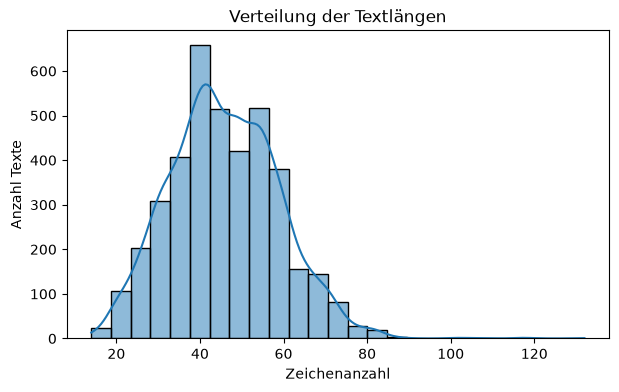

In [34]:
#Eine Spalte:
import matplotlib.pyplot as plt                                 #Diagrammfunktionen laden
import seaborn as sns                                           #Statistische Diagrammfunktionen laden

df_autoscout['type_len'] = df_autoscout['type'].apply(len)      #Zeichenanzahl in einer neuen Spalte speichern
                                                                #apply(len): len() auf jeden Text anwenden
display(df_autoscout[['type', 'type_len']].head())              #Ausgangstext und Länge für die ersten fünf Zeilen anzeigen

plt.figure(figsize=(7, 4))                                      #Neue Abbildung mit 7 × 4 Zoll erstellen
sns.histplot(df_autoscout['type_len'], bins=25, kde=True)       #Histogramm mit 25 Intervallen zeichnen
                                                                #kde=True: geglättete Verteilungskurve ergänzen
plt.title('Verteilung der Textlängen')                          #Diagrammtitel setzen
plt.xlabel('Zeichenanzahl')                                     #x-Achse beschriften
plt.ylabel('Anzahl Texte')                                      #y-Achse beschriften
plt.show()                                                      #Diagramm anzeigen

#ANPASSEN: df_autoscout überall an deinen Tabellennamen
#ANPASSEN: type an die vorhandene Textspalte; type_len an die neue Längenspalte
#OPTIONAL: bins, figsize und Beschriftungen ändern; kde=False für keine Kurve
#BEI FEHLENDEN TEXTEN: .str.len() statt .apply(len) verwenden

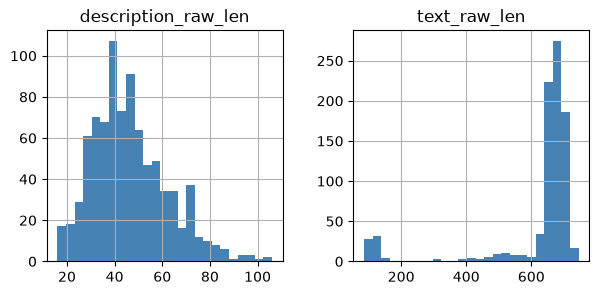

In [35]:
#Mehrere Spalten
import matplotlib.pyplot as plt                                                     #Diagrammfunktionen laden

df_apartments['description_raw_len'] = df_apartments['description_raw'].str.len()   #Beschreibungslängen speichern
df_apartments['text_raw_len'] = df_apartments['text_raw'].str.len()                 #Textlängen speichern
                                                                                    #.str.len(): Zeichen zählen; fehlende Texte bleiben fehlend

ax = df_apartments[['description_raw_len', 'text_raw_len']].hist(
    bins=25,                                                                        #Pro Längenspalte ein Histogramm mit 25 Intervallen erstellen
    figsize=(7, 3),                                                                 #Gesamtgrösse der Abbildung in Zoll
    color='steelblue'                                                               #Balkenfarbe festlegen
)

for axis in ax.flatten():                                                           #Achsenanordnung abflachen und jede Diagrammachse durchlaufen
    axis.set_ylim(bottom=0)                                                         #y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen

plt.show()                                                                          #Histogramme anzeigen

#ANPASSEN: df_apartments überall an deinen Tabellennamen
#ANPASSEN: description_raw und text_raw an die vorhandenen Textspalten
#ANPASSEN: description_raw_len und text_raw_len überall an die neuen Längenspalten
#OPTIONAL: bins, figsize und color ändern
#BEI VORGEGEBENER Y-GRENZE: z. B. axis.set_ylim(0, 300) verwenden

### Create binary (0/1) Variable
Text nach Suchbegriffen durchsuchen, als 0/1 markieren und Treffer zählen

Prüft jede Zeile auf mind. einen Suchbegriff und speichert eine 1 bei einem Treffer, sonst eine 0; anschliessend werden die Treffer gezählt und angezeigt

- Suchbegriffe mit | verbinden, das bedeutet ODER. Diesen String der Variable pattern zuweisen
- Ausgangsspalte: vorhandene Textspalte, die durchsucht wird
- Zielspalte: neue Spalte für die 0/1-Markierung
- Die Suche beachtet Gross-/Kleinschreibung; für eine Suche unabhängig davon case=False ergänzen
- Es werden auch Wortteile gefunden

In [36]:
# Create a search pattern
pattern = 'RENOVIERT|SANIERT|NEUBAU'                                            #Suchbegriffe festlegen; | bedeutet ODER – ein passender Begriff genügt

# Create a binary (0/1) variable
df_apartments['Neuer Spaltennamen'] = df_apartments['description_raw'].str.contains(pat=pattern, na=False).astype(int)   
                                                                                #Text jeder Zeile prüfen und Ergebnis in match speichern
                                                                                #str.contains(): gesuchter Begriff enthalten → True, sonst False
                                                                                #astype(int): True → 1, False → 0; na=False: fehlender Text → kein Treffer
# Count matching rows
print("Anzahl Treffer:", df_apartments['Neuer Spaltennamen'].sum())                          #Einsen addieren: Jede passende Zeile zählt einmal

# Show matching rows
df_apartments[['description_raw', 'Neuer Spaltennamen']].loc[df_apartments['Neuer Spaltennamen'] == 1]         
                                                                                #Ausgangstext und Markierung nur für Treffer anzeigen
                                                                                #[[...]]: Spalten auswählen; .loc[...]: Zeilen mit match == 1 behalten

#ANPASSEN: Suchbegriffe in pattern
#ANPASSEN: description_raw an deine Spalte (die alte Spalte!)
#ANPASSEN: Neuer Spaltenname an den gewünschten Zielspaltennamen
#ANPASSEN: df überall, falls deine Tabelle anders heisst
#OPTIONAL: Weitere Spalten in der Anzeige ergänzen, bspw. df[['description_raw', 'rooms', 'area', 'price', 'match']].loc[df['match'] == 1]
#OPTIONAL: Gross-/Kleinschreibung ignorieren → str.contains(pat=pattern, case=False, na=False)

Anzahl Treffer: 9


,description_raw,Neuer Spaltennamen
33,"«VIEL RAUM, RENOVIERT UND ZENTRAL»",1
202,«NEUBAU - EXKLUSIV WOHNEN AUF ZWEI ETAGEN»,1
256,«HELLER NEUBAU - VIEL PLATZ UND SCHÖNEM BALKON»,1
495,«2.5 Zimmerwohnung NEUBAU»,1
496,«2.5 Zimmerwohnung NEUBAU»,1
793,«2.5 Zimmerwohnung NEUBAU»,1
835,«2.5 Zimmerwohnung NEUBAU»,1
836,«3.5 Zimmerwohnung NEUBAU»,1
837,«2.5 Zimmerwohnung NEUBAU»,1


### Create Variable
Neue Spalte berechnen: Zwei Zahlenspalten verrechnen und Ergebnis runden

Berechnet für jede Zeile einen neuen Wert aus zwei vorhandenen Zahlenspalten und speichert ihn in einer zusätzlichen Spalte

Bsp.: Preis durch PS-Zahl teilen → Preis pro PS

- ANPASSEN: Ausgangsspalten, Zielspalte und Anzahl Nachkommastellen
- Rechenzeichen: / Division, * Multiplikation, + Addition, - Subtraktion
- Beide Ausgangsspalten müssen numerisch sein; bei einer Division darf der Nenner nicht 0 sein
- Fehlende Ausgangswerte ergeben einen fehlenden Ergebniswert

#### Einschub: Voraussetzung - Numerische Spalten vor der Berechnung erstellen

Für den Preis pro PS müssen die Spalten `price` und `hp` bereits als Zahlen in derselben Tabelle vorhanden sein
Die Rohdaten enthalten zunächst nur `Price_Raw` und `HP_Raw` mit Texten wie `"CHF 22'500.–"` und `"245 PS"`

1. Spaltennamen kleinschreiben: `df_autoscout.columns = df_autoscout.columns.str.lower()` macht bspw. aus `Price_Raw` den Namen `price_raw`; die Inhalte bleiben unverändert

2. Preis- und PS-Regex-Bausteine ausführen: Diese extrahieren die Zahlen aus `price_raw` und `hp_raw` und speichern sie als neue numerische Spalten `price` und `hp`

3. In beiden Bausteinen überall `df_autoscout` statt `df` verwenden, damit die neuen Spalten in der richtigen Tabelle entstehen

4. Anschliessend den Preis durch die PS-Zahl teilen: `df_autoscout['price_per_hp'] = round(df_autoscout['price'] / df_autoscout['hp'], 2)`

ANPASSEN: Tabellenname und Spaltennamen an deine Aufgabe
Die Kleinschreibung der Spaltennamen allein wandelt keine Texte in Zahlen um

In [37]:
import re                                                                       #Regex-Funktionen laden
import pandas as pd                                                             #pandas für Tabellen laden

df_autoscout.columns = df_autoscout.columns.str.lower()                         #Spaltennamen kleinschreiben: Price_Raw → price_raw

# Numerische Preisspalte erstellen
price = []                                                                      #Leere Liste für die Preise erstellen
for i in df_autoscout['price_raw']:                                             #Jeden Preistext durchlaufen
    d1 = re.findall(r"CHF\s*([\d'’]+)\.[—–-]", i)                               #Betrag zwischen CHF und Preisendung erfassen
    try:
        d2 = d1[0].strip().replace("'", "").replace("’", "")                    #Ersten Treffer nehmen und Tausenderapostrophe entfernen
    except IndexError:                                                          #Kein passender Preis gefunden
        d2 = None                                                               #Fehlenden Wert verwenden
    price.append(d2)                                                            #Ergebnis zur Liste hinzufügen

df_autoscout['price'] = pd.Series(price, index=df_autoscout.index, dtype="Int64") #Neue numerische Preisspalte speichern; fehlende Werte erlauben

# Numerische PS-Spalte erstellen
hp = []                                                                         #Leere Liste für die PS-Werte erstellen
for i in df_autoscout['hp_raw']:                                                #Jede PS-Angabe durchlaufen
    d1 = re.findall(r"\d+", i)                                                  #Ziffernfolgen finden; "245 PS" → ["245"]
    try:
        d2 = int(''.join(d1))                                                   #Ziffernfolgen verbinden und in eine ganze Zahl umwandeln
    except ValueError:                                                          #Keine umwandelbare Zahl gefunden
        d2 = None                                                               #Fehlenden Wert verwenden
    hp.append(d2)                                                               #Ergebnis zur Liste hinzufügen

df_autoscout['hp'] = pd.Series(hp, index=df_autoscout.index, dtype="Int64")     #Neue numerische PS-Spalte speichern; fehlende Werte erlauben

# Umwandlung kontrollieren
display(df_autoscout[['price_raw', 'price', 'hp_raw', 'hp']].head())            #Rohtexte und extrahierte Zahlen vergleichen
print(df_autoscout[['price', 'hp']].dtypes)                                     #Prüfen, ob beide neuen Spalten numerisch sind

,price_raw,price,hp_raw,hp
0,CHF 22'500.–,22500,245 PS,245
1,CHF 23'749.–,23749,184 PS,184
2,CHF 18'500.–,18500,306 PS,306
3,CHF 36'000.–,36000,360 PS,360
4,CHF 48'500.–,48500,252 PS,252


price    Int64
hp       Int64
dtype: object


In [38]:
# Create the new variable
df_autoscout['price_per_hp'] = round(df_autoscout['price'] / df_autoscout['hp'], 2)   
                                                        #Preis durch PS-Zahl teilen und Ergebnis als neue Spalte speichern
                                                        #round(..., 2): auf zwei Nachkommastellen runden

# Show values
df_autoscout[['price', 'hp', 'price_per_hp']].head()    #Ausgangswerte und Ergebnis für die ersten fünf Zeilen anzeigen
                                                        #[[...]]: Spalten auswählen; head(): erste fünf Zeilen

#ANPASSEN: 'price' und 'hp' an die vorhandenen Zahlenspalten, in Berechnung und Anzeige
#ANPASSEN: 'price_per_hp' an den gewünschten neuen Spaltennamen, links vom = und in der Anzeige
#ANPASSEN: / an die Rechenoperation; 2 an die Anzahl Nachkommastellen
#ANPASSEN: df überall, falls deine Tabelle anders heisst
#OPTIONAL: .head() weglassen, um alle Zeilen anzufordern; weitere Anzeigespalten in [[...]] ergänzen

,price,hp,price_per_hp
0,22500,245,91.84
1,23749,184,129.07
2,18500,306,60.46
3,36000,360,100.0
4,48500,252,192.46


### Include current datetime as time stamp
Aktuelles Datum und Uhrzeit als Zeitstempel speichern

Speichert den Zeitpunkt der Ausführung als Text in einer neuen Spalte; alle Zeilen erhalten denselben Zeitstempel

Bsp.: „2026-10-16 01:03:53“ dokumentiert, wann der Code ausgeführt wurde
Bei erneutem Ausführen wird der bisherige Zeitstempel überschrieben

- ANPASSEN: Tabellenname, Zielspaltenname und bei Bedarf Datumsformat
- %Y: vierstelliges Jahr; %m: Monat; %d: Tag
- %H: Stunde; %M: Minute; %S: Sekunde

In [39]:
from datetime import datetime                                                   #Werkzeug für Datum und Uhrzeit laden

df_apartments['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')       #Aktuellen Zeitpunkt als Text in jeder Zeile speichern
                                                                                #now(): aktueller Zeitpunkt; strftime(): gewünschtes Textformat erzeugen
df_apartments['timestamp'].head()                                               #Zeitstempel der ersten fünf Zeilen anzeigen

#ANPASSEN: df überall an den Namen deiner Tabelle
#ANPASSEN: timestamp an den gewünschten neuen Spaltennamen – an beiden Stellen
#OPTIONAL: '%Y-%m-%d' für nur Datum oder '%d.%m.%Y %H:%M' für Tag.Monat.Jahr Stunde:Minute
#NICHTS ANPASSEN: übriger Code für einen Zeitstempel als Text

0    2026-10-16 22:08:48
1    2026-10-16 22:08:48
2    2026-10-16 22:08:48
3    2026-10-16 22:08:48
4    2026-10-16 22:08:48
Name: timestamp, dtype: str

# Discretization of Numerical Data

Folien
- Data Discretization (also called “Data Binning”) is a technique that involves dividing a continuous variable into a finite number of intervals or “bins”
- These bins are then treated as categorical variables. Data binning helps to reduce the effects of minor observation errors and helps in managing noise in data, especially when the data is too granular or detailed

- Bei der Diskretisierung werden numerische Werte in geordnete Kategorien eingeteilt, beispielsweise das Alter 5 in „0–10“, 24 und 29 in „über 20 bis 30“ und 72 in „über 70 bis 80“. Das vereinfacht Vergleiche, verliert aber Details, weil unterschiedliche Werte wie 24 und 29 derselben Klasse zugeordnet werden
- Teilt eine stetige Variable in eine endliche Zahl von Intervallen oder Klassen, auf Englisch bins. Diese Klassen werden dann als kategoriale Variable behandelt
- Das Beispiel verwendet die pandas-Funktion cut. Ein Dataframe enthält die Alterswerte 5, 12, 17, 24, 29, 35, 45, 52, 60 und 72. Die Klassengrenzen liegen bei 0, 10, 20 und so weiter bis 80, mit den Beschriftungen 0 bis 10, 11 bis 20 und so weiter bis 71 bis 80. Die Ausgabe zeigt jedes Alter mit seiner Altersklasse, zum Beispiel 5 in 0 bis 10, 24 in 21 bis 30 und 72 in 71 bis 80

#### Numerische Werte in Klassen einteilen: cut und qcut

Ordnet Zahlen geordneten Kategorien zu, beispielsweise Preise den Klassen „günstig“, „mittel“ und „teuer“, und speichert die Klasse in einer neuen Spalte

- pd.cut(..., bins=3): Drei gleich breite Zahlenintervalle; die Anzahl Datensätze je Klasse kann unterschiedlich sein
- pd.qcut(..., q=3): Drei Klassen mit ungefähr gleich vielen Datensätzen; die Zahlenintervalle können unterschiedlich breit sein
- Nur eine der beiden Varianten ausführen
- Die Anzahl Beschriftungen muss zur Anzahl Klassen passen
- Fehlende Zahlen erhalten keine Klasse und werden im Balkendiagramm nicht mitgezählt
- Achtung bei qcut: Viele gleiche Werte können identische Klassengrenzen erzeugen und einen Fehler auslösen; dann Anzahl Klassen oder Einteilung prüfen

In [40]:
#An der Prüfung eine der beiden Varianten nehmen. Für "Create a 1x2 grid" siehe V4 Ü3.2
# Variante 1: Gleich breite Zahlenintervalle
df_autoscout['price_category'] = pd.cut(df_autoscout['price_per_hp'],
                              bins=3,                                           #Wertebereich in drei gleich breite Intervalle teilen
                              labels=['günstig', 'mittel', 'teuer'])            #Klassen von niedrigen zu hohen Werten beschriften

# Variante 2: Ungefähr gleich viele Datensätze je Klasse
df_autoscout['price_category'] = pd.qcut(df_autoscout['price_per_hp'],
                               q=3,                                     #Quantilgrenzen für drei ungefähr gleich grosse Gruppen bestimmen
                               labels=['günstig', 'mittel', 'teuer'])   #Klassen von niedrigen zu hohen Werten beschriften

df_autoscout[['price_per_hp', 'price_category']].head()                         #Zahlenwert und zugeordnete Klasse für die ersten fünf Zeilen anzeigen

#NUR EINE VARIANTE AUSFÜHREN: Beide schreiben in dieselbe Zielspalte
#ANPASSEN: df überall an deinen Tabellennamen, z. B. df_autoscout
#ANPASSEN: price_per_hp an die vorhandene numerische Spalte
#ANPASSEN: price_category an den gewünschten neuen Spaltennamen
#ANPASSEN: bins bzw. q an die Klassenanzahl; labels an passende Beschriftungen

,price_per_hp,price_category
0,91.84,mittel
1,129.07,teuer
2,60.46,günstig
3,100.0,mittel
4,192.46,teuer


# One-Hot Encoding
- Technique that converts categorical variables into a format that can be provided to machine learning algorithms. Specifically, it transforms categorical data, which can have multiple categories, into vectors with binary values
- One-Hot-Encoding wandelt eine kategoriale Spalte in mehrere 0/1-Spalten um – beispielsweise wird „Farbe“ zu „Rot“, „Blau“ und „Grün“, wobei jede Zeile bei ihrer Farbe eine 1 und bei den anderen eine 0 erhält
- Bsp.: Eine Spalte Color mit den Werten Red, Green, Blue, Green und Red. Nach dem Kodieren gibt es drei Spalten Color_Red, Color_Green und Color_Blue. In jeder Zeile steht eine 1 in der Spalte der passenden Farbe und sonst 0. Die erste Zeile, Red, wird also zu 1, 0, 0

- Erstellt für jede Kategorie eine eigene Spalte: Gehört eine Zeile zu dieser Kategorie, erhält sie dort eine 1, sonst eine 0
- Bsp.: Aus der Preisklasse „günstig“ entstehen die Spalten „price_category_günstig“, „price_category_mittel“ und „price_category_teuer“ mit den Werten 1, 0 und 0
- Die ursprüngliche Kategoriespalte wird ersetzt; alle anderen Spalten bleiben erhalten
- Voraussetzung: Die Kategoriespalte wurde bereits erstellt, bspw. mit cut oder qcut

In [41]:
#VORAUSSETZUNG: Zuerst den cut()- oder qcut()-Block (Dicretization) ausführen; er erstellt die Kategoriespalte
#ANPASSEN: Tabellenname und Kategoriespalte an den vorherigen Block – Spaltenname links vom = übernehmen
#BEISPIEL: df_autoscout['price_category'] = pd.qcut(...) → columns=['price_category'], Anzeige mit like='price_category_'

# One-Hot-Encoding
df_autoscout = pd.get_dummies(df_autoscout, #Ergebnis in df_autoscout speichern
                               columns=['price_category'], #Zuvor erstellte Kategoriespalte in Dummy-Spalten umwandeln
                               drop_first=False, #Alle Kategorien behalten
                               dtype=int) #Direkt 0/1 speichern

# Show dummy variables
df_autoscout.filter(like='price_category_').head() #Neue Dummy-Spalten der ersten fünf Zeilen anzeigen

#ANPASSEN: df_autoscout überall an den Namen deiner Tabelle
#ANPASSEN: price_category an die Kategoriespalte aus dem vorherigen cut()- oder qcut()-Block
#ANPASSEN: price_category_ in der Anzeige an denselben Spaltennamen plus Unterstrich
#NICHTS ANPASSEN: dtype=int für 0/1; drop_first=False, wenn alle Kategorien behalten werden sollen
#ACHTUNG: One-Hot-Encoding ersetzt die Kategoriespalte; vor erneutem Ausführen zuerst den cut()- oder qcut()-Block ausführen

,price_category_günstig,price_category_mittel,price_category_teuer
0,0,1,0
1,0,0,1
2,1,0,0
3,0,1,0
4,0,0,1


# Scaling (Data Scaling)

- Data scaling is a preprocessing step in machine learning and data analysis that involves adjusting the values of numerical data to a common scale, without distorting differences in the ranges of values
- Its primary purpose is to bring all the features into a comparable range, which can significantly improve the performance of machine learning algorithms, especially those that are sensitive to the magnitude of the data like linear & logistic regression and k-nearest neighbors
- Data Scaling  bringt numerische Merkmale auf eine vergleichbare Grössenordnung, damit grosse Zahlenwerte ein Modell nicht allein wegen ihrer Skala stärker beeinflussen
- Bsp. Kilometerstände von 0-200’000 km und Leistungen von 0-500 PS werden jeweils auf den Bereich 0–1 skaliert, sodass 100’000 km und 250 PS beide den Wert 0.5 erhalten

### Min-Max Scaling

### Min-Max-Skalierung: Zahlenwerte auf den Bereich 0 bis 1 bringen
Ist ein Skalierungsverfahren, bei dem von jedem Wert das Minimum abgezogen und das Ergebnis durch die Spannweite (Maximum − Minimum) geteilt wird, sodass alle Werte zwischen 0 und 1 liegen, ohne die Form der Verteilung zu verändern.

- Zieht von jedem Wert das Minimum ab und teilt durch die Spannweite: (Wert − Minimum) / (Maximum − Minimum)

- Bsp.: Bei Kilometerständen zwischen 20’000 und 120’000 km wird 20’000 zu 0, 70’000 zu 0.5 und 120’000 zu 1

- Die ursprüngliche Zahlenspalte bleibt erhalten; die skalierten Werte werden in einer neuen Spalte gespeichert

- Die Verteilungsform bleibt gleich, nur die Skala verändert sich

- Voraussetzung: Die Ausgangsspalte ist numerisch und enthält mindestens zwei unterschiedliche Werte, sonst ist der Nenner 0

#### By hand
Bei **By hand** wird die Skalierung mithilfe einer mathematischen Formel selbst berechnet, während **scikit-learn** die Berechnung mit vorgefertigten Methoden automatisiert. `fit()` bestimmt die benötigten Parameter (z. B. Minimum und Maximum), und `transform()` skaliert die Werte damit. **Beide Verfahren liefern praktisch identische Ergebnisse**, was mit `np.allclose()` überprüft werden kann. Der Vorteil von scikit-learn ist, dass die ermittelten Skalierungsparameter gespeichert und auf neue Daten angewendet werden können.

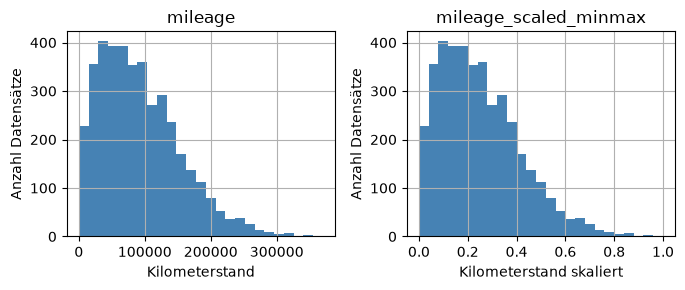

In [42]:
# Min-Max scaling
df_autoscout['mileage_scaled_minmax'] = ((df_autoscout['mileage'] - df_autoscout['mileage'].min())                    #Minimum von jedem Wert abziehen
                               / (df_autoscout['mileage'].max() - df_autoscout['mileage'].min()))           #Durch die Spannweite teilen; Ergebnis zwischen 0 und 1

# Compare original and scaled values
ax = df_autoscout[['mileage', 'mileage_scaled_minmax']].hist(
    bins=25,                                                                            #Pro Spalte ein Histogramm mit 25 Intervallen erstellen
    figsize=(7, 3),                                                                     #Gesamtgrösse der Abbildung in Zoll
    color='steelblue')                                                                  #Balkenfarbe festlegen

for axis, label in zip(ax.flatten(), ['Kilometerstand', 'Kilometerstand skaliert']):    #Achsen und Beschriftungen paarweise durchlaufen
                                                                                        #flatten(): Achsenanordnung abflachen; zip(): paarweise verbinden
    axis.set_ylim(bottom=0)                                                             #y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen
    axis.set_xlabel(label)                                                              #Jeweils passende x-Achsenbeschriftung setzen
    axis.set_ylabel('Anzahl Datensätze')                                                #y-Achse beschriften

plt.tight_layout()                                                                      #Abstände zwischen den Diagrammen anpassen
plt.show()                                                                              #Beide Histogramme anzeigen

#ANPASSEN: df überall an deinen Tabellennamen, z. B. df_autoscout oder df_apartments
#ANPASSEN: mileage überall an die vorhandene numerische Ausgangsspalte
#ANPASSEN: mileage_scaled_minmax überall an den gewünschten neuen Spaltennamen
#ANPASSEN: Die beiden Beschriftungen in der zip()-Liste an dein Merkmal
#OPTIONAL: bins, figsize und color ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 500) statt axis.set_ylim(bottom=0)

#### Min-Max Scaling (scikit-learn)
- **Zweck:** Numerische Werte mithilfe von `MinMaxScaler()` auf den Bereich **0 bis 1** skalieren, damit unterschiedlich grosse Zahlenwerte vergleichbar werden.
- **Funktionsweise:** `MinMaxScaler()` verwendet dieselbe Formel wie die manuelle Min-Max-Skalierung: `(Wert − Minimum) / (Maximum − Minimum)`. Das Minimum wird zu 0, das Maximum zu 1.
- **Voraussetzung:** Die zu skalierende Spalte muss numerische Werte enthalten. Für den Vergleich mit `np.allclose()` muss die manuelle Skalierung bereits durchgeführt worden sein.
- **Kontrolle:** `np.allclose()` vergleicht die manuell berechneten und die mit scikit-learn skalierten Werte. Das Ergebnis `True` bestätigt, dass beide Verfahren innerhalb kleiner numerischer Toleranzen übereinstimmen.

In [43]:
# Min-Max scaling (scikit-learn version)
from sklearn.preprocessing import MinMaxScaler                          #MinMaxScaler importieren: numerische Werte standardmässig auf 0 bis 1 skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MinMaxScaler() #Scaler-Objekt für die Min-Max-Skalierung erstellen
df_autoscout['mileage_scaled_minmax_sklearn'] = scaler.fit_transform(   #Skalierte Werte in neuer Spalte speichern
    df_autoscout[['mileage']]).ravel()                                  #fit_transform(): Minimum und Maximum bestimmen und Werte auf 0 bis 1 skalieren
                                                                        #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                        #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_autoscout['mileage_scaled_minmax'],                #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_autoscout['mileage_scaled_minmax_sklearn']))       #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen

#ANPASSEN: df_autoscout überall an den verwendeten DataFrame anpassen (z.B. df_apartments)
#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_minmax_sklearn an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: mileage_scaled_minmax an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: MinMaxScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuelle Skalierung muss bereits durchgeführt worden sein, damit np.allclose() funktioniert

True


### Max-Absolute Scaling (manuell)

Ist ein Skalierungsverfahren, bei dem jeder Wert durch den grössten Absolutwert des Merkmals geteilt wird, sodass alle Werte zwischen −1 und 1 liegen, ohne den Nullpunkt oder die Form der Verteilung zu verändern.
- **Zweck:** Numerische Werte durch den grössten Absolutwert der Spalte dividieren, um sie auf den Bereich **−1 bis 1** zu skalieren (bei ausschliesslich positiven Werten: 0 bis 1).
- **Formel:** `Wert / max(abs(alle Werte))` – der betragsmässig grösste Wert wird zu −1 oder 1; der Wert 0 bleibt unverändert.
- **Unterschied zu Min-Max:** Bei Max-Absolute wird kein Minimum abgezogen. Deshalb bleibt der Nullpunkt erhalten, während bei Min-Max der kleinste Wert zu 0 wird.
- **Erkenntnis:** Die Skalierung verändert die Grössenordnung, aber nicht die Verteilungsform oder die relativen Abstände. Die Histogramme zeigen dieselbe Verteilung, jedoch mit unterschiedlichen x-Achsenwerten.

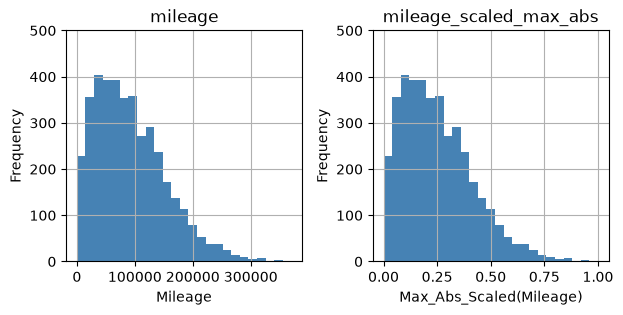

In [44]:
# Max-Absolute scaling of the variable 'mileage' (by hand)
df_autoscout['mileage_scaled_max_abs'] = df_autoscout['mileage'] / df_autoscout['mileage'].abs().max() #Jeden Kilometerstand durch den grössten Absolutwert dividieren
                                                                                    #abs(): Absolutwerte bilden; max(): grössten Absolutwert bestimmen
                                                                                    #Ergebnis: Werte zwischen -1 und 1 (bei positiven Kilometerständen 0 bis 1)

# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'
ax = df_autoscout[['mileage', 'mileage_scaled_max_abs']].hist(bins=25,              #Originale und skalierte Kilometerstände als zwei Histogramme darstellen
                                                             figsize=(7, 3),        #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                             color='steelblue')     #bins=25: 25 Intervalle; color: Balkenfarbe
                                                                                    #hist(): Häufigkeitsverteilung darstellen; ax speichert die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Max_Abs_Scaled(Mileage)']):       #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                    #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(0, 500)                                                           #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                          #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                    #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                          #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall an den verwendeten DataFrame anpassen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_max_abs an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: ['Mileage', 'Max_Abs_Scaled(Mileage)'] an die gewünschten x-Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: abs(), max(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show() bleiben unverändert

#### Max-Absolute Scaling (scikit-learn)

- **Zweck:** Numerische Werte mit `MaxAbsScaler()` automatisch durch den grössten Absolutwert skalieren (Bereich −1 bis 1).
- **Funktionsweise:** `fit_transform()` bestimmt den grössten Absolutwert der Spalte und dividiert sämtliche Werte dadurch. Im Gegensatz zu Min-Max wird kein Minimum abgezogen, weshalb 0 unverändert bleibt.
- **Voraussetzung:** Die Ausgangsspalte muss numerisch sein. Für den Vergleich mit `np.allclose()` muss die manuelle Max-Absolute-Skalierung bereits durchgeführt worden sein.
- **Kontrolle:** `np.allclose()` überprüft, ob die manuelle Berechnung und `MaxAbsScaler()` innerhalb kleiner numerischer Toleranzen übereinstimmen. Das Ergebnis `True` bestätigt, dass beide Verfahren praktisch identische Werte liefern.

In [45]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MaxAbsScaler                            #MaxAbsScaler importieren: Werte durch den grössten Absolutwert skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MaxAbsScaler() #Scaler-Objekt für die Max-Absolute-Skalierung erstellen
df_autoscout['mileage_scaled_max_abs_sklearn'] = scaler.fit_transform(    #Skalierte Kilometerstände in neuer Spalte speichern
    df_autoscout[['mileage']]).ravel()                                    #fit_transform(): Grössten Absolutwert bestimmen und Werte dadurch dividieren
                                                                          #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                          #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_autoscout['mileage_scaled_max_abs'],                 #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_autoscout['mileage_scaled_max_abs_sklearn']))        #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                          #True: Beide Verfahren liefern praktisch identische Werte

#ANPASSEN: df_autoscout überall an den verwendeten DataFrame anpassen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_max_abs_sklearn an den gewünschten neuen Spaltennamen anpassen
#ANPASSEN: mileage_scaled_max_abs an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: MaxAbsScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuell skalierte Spalte muss bereits existieren, damit np.allclose() funktioniert

True


### Robust Scaling

**Zweck:** Numerische Werte mithilfe des Medians und des Interquartilsabstands (IQR) skalieren. Besonders geeignet für Daten mit **Ausreissern**, da Median und IQR weniger empfindlich gegenüber extremen Werten sind.
- **Formel:** `(Wert − Median) / (Q3 − Q1)` – vom ursprünglichen Wert den Median abziehen und durch den Interquartilsabstand teilen.
- **Methoden:** `median()` bestimmt den mittleren Wert (50. Perzentil); `quantile(0.25)` bestimmt das untere Quartil (Q1) und `quantile(0.75)` das obere Quartil (Q3). Die Differenz `Q3 − Q1` ergibt den IQR und beschreibt die Streuung der mittleren 50 % der Daten.
- **Erkenntnis:** Der Median wird zu 0; Werte darunter werden negativ, Werte darüber positiv. Es gibt keinen festen Wertebereich wie bei Min-Max Scaling. Die Verteilungsform bleibt erhalten, die x-Achse wird verschoben und skaliert.
- **Unterschied zu Min-Max und Max-Absolute:** Robust Scaling verwendet Median und IQR statt Minimum oder Maximum. Dadurch beeinflussen Ausreisser die Skalierung weniger stark, bleiben aber weiterhin im Datensatz enthalten.

#### Robus Scaling (manuell)

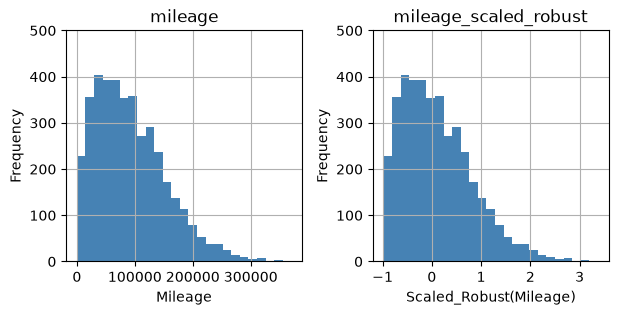

In [46]:
# Robust scaling of the variable 'mileage' (by hand)
df_autoscout['mileage_scaled_robust'] = (df_autoscout['mileage'] - df_autoscout['mileage'].median()) / \
    (df_autoscout['mileage'].quantile(0.75)                         #quantile(0.75): 75. Perzentil (Q3) bestimmen
     - df_autoscout['mileage'].quantile(0.25))                      #quantile(0.25): 25. Perzentil (Q1) bestimmen
                                                                    #median(): mittleren Wert bestimmen (50. Perzentil)
                                                                    #Formel: (Wert - Median) / (Q3 - Q1); Q3 - Q1 = IQR
                                                                    #Ergebnis: Median wird 0; Ausreisser beeinflussen die Skalierung weniger

# Histogram of the variable 'mileage' and 'mileage_scaled_robust'
ax = df_autoscout[['mileage', 'mileage_scaled_robust']].hist(bins=25,           #Originale und skalierte Werte als zwei Histogramme darstellen
                                                            figsize=(7, 3),     #figsize: Abbildungsgrösse (Breite × Höhe in Zoll)
                                                            color='steelblue')  #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                                #color: Balkenfarbe; ax speichert die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Robust(Mileage)']):    #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln
                                                                                #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_robust an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Scaled_Robust(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: median(), quantile(0.75), quantile(0.25), hist(), flatten(), zip() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit IQR > 0; pandas und matplotlib.pyplot als plt müssen importiert sein

#### Robust Scaling (scikit-learn)

- **Zweck:** Numerische Werte mit `RobustScaler()` automatisch anhand des Medians und des Interquartilsabstands (IQR) skalieren, um den Einfluss von Ausreissern zu reduzieren.
- **Funktionsweise:** `fit_transform()` bestimmt den Median und den IQR (`Q3 − Q1`) und skaliert die Werte mit der Formel `(Wert − Median) / IQR`.
- **Erkenntnis:** Der Median wird zu 0. Werte darunter werden negativ, Werte darüber positiv. Anders als bei Min-Max Scaling gibt es keinen festen Wertebereich.
- **Kontrolle:** `np.allclose()` vergleicht die manuelle Berechnung mit der scikit-learn-Version. `True` bestätigt, dass beide Verfahren innerhalb kleiner numerischer Toleranzen übereinstimmen.
- **Voraussetzung:** Für den Vergleich muss die manuell skalierte Spalte bereits existieren.

In [47]:
# Robust scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import RobustScaler                          #RobustScaler importieren: Werte anhand von Median und IQR skalieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = RobustScaler() #Scaler-Objekt für die robuste Skalierung erstellen
df_autoscout['mileage_scaled_robust_sklearn'] = scaler.fit_transform(   #Robust skalierte Kilometerstände in neuer Spalte speichern
    df_autoscout[['mileage']]).ravel()                                  #fit_transform(): Median und IQR bestimmen und Werte damit skalieren
                                                                        #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                        #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df_autoscout['mileage_scaled_robust'],                #Manuelle und sklearn-Skalierung miteinander vergleichen
                  df_autoscout['mileage_scaled_robust_sklearn']))       #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                        #True: Beide Verfahren liefern praktisch identische Ergebnisse

#ANPASSEN: df_autoscout überall an den verwendeten DataFrame anpassen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu skalierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_robust_sklearn an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: mileage_scaled_robust an den Namen der zuvor manuell skalierten Spalte anpassen
#NICHTS ANPASSEN: RobustScaler(), fit_transform(), ravel() und np.allclose() bleiben unverändert
#VORAUSSETZUNG: Die manuelle Robust-Skalierung muss bereits ausgeführt worden sein, damit np.allclose() funktioniert

True


### Data Standardization (Z-Score Normalization)

- **Definition:** Standardisierung ist ein Skalierungsverfahren, bei dem numerische Werte so umgerechnet werden, dass sie einen **Mittelwert von 0 und eine Standardabweichung von 1** aufweisen.
- **Zweck:** Numerische Merkmale mit unterschiedlichen Grössenordnungen vergleichbar machen, damit grosse Zahlenwerte ein Modell nicht allein aufgrund ihrer Skala stärker beeinflussen. Durch die Standardisierung wird zudem erkennbar, wie viele Standardabweichungen ein Wert über oder unter dem Mittelwert liegt.
- **Formel:** `(Wert − Mittelwert) / Standardabweichung` – von jedem Wert wird der Mittelwert abgezogen und das Ergebnis durch die Standardabweichung geteilt.
- **Mittelwert (μ):** Durchschnitt aller Werte eines Merkmals; wird durch die Standardisierung auf 0 verschoben.
- **Standardabweichung (σ):** Mass für die Streuung der Werte um den Mittelwert; wird durch die Standardisierung auf 1 gebracht.
- **Erkenntnis:** Werte über dem Mittelwert werden positiv, Werte darunter negativ. Die Verteilungsform bleibt unverändert und die Daten werden **nicht automatisch normalverteilt**. Im Gegensatz zu Min-Max Scaling gibt es keinen festen Wertebereich. In scikit-learn wird dafür `StandardScaler()` verwendet.

#### Data Standardization / Z-Score Normalization (manuell)

- **Definition:** Standardisierung ist ein Skalierungsverfahren, bei dem numerische Werte so umgerechnet werden, dass sie einen Mittelwert von 0 und eine Standardabweichung von 1 aufweisen.
- **Zweck:** Merkmale unterschiedlicher Grössenordnungen vergleichbar machen, damit grosse Zahlenwerte ein Modell nicht allein aufgrund ihrer Skala stärker beeinflussen. Ein Z-Score zeigt zudem, wie viele Standardabweichungen ein Wert vom Mittelwert entfernt liegt.
- **Formel:** `(Wert − Mittelwert) / Standardabweichung` – von jedem Wert den Mittelwert abziehen und durch die Standardabweichung dividieren.
- **Methoden:** `mean()` berechnet den arithmetischen Mittelwert; `std()` bestimmt die Standardabweichung und damit die Streuung der Werte um den Mittelwert.
- **Erkenntnis:** Der Mittelwert wird zu 0 und die Standardabweichung zu 1. Werte über dem Mittelwert werden positiv, darunter negativ. Es gibt keinen festen Wertebereich. Die Verteilungsform bleibt unverändert und die Daten werden nicht automatisch normalverteilt.

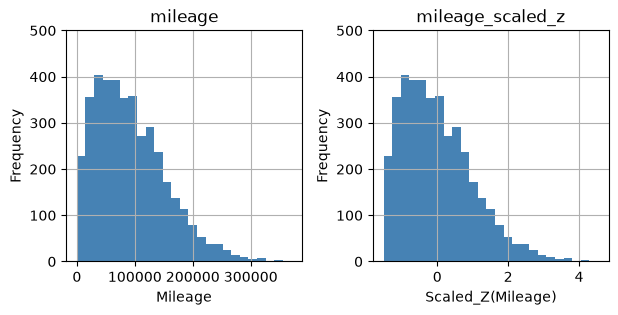

In [48]:
# Z-score Normalization of the variable 'mileage' (by hand)
df_autoscout['mileage_scaled_z'] = ((df_autoscout['mileage'] - df_autoscout['mileage'].mean())  #Von jedem Kilometerstand den Mittelwert abziehen
                                   / df_autoscout['mileage'].std())                             #Durch die Standardabweichung dividieren
                                                                                                #mean(): arithmetischen Mittelwert berechnen
                                                                                                #std(): Standardabweichung bestimmen (standardmässig Stichprobe, ddof=1)
                                                                                                #Ergebnis: Mittelwert ≈ 0 und Standardabweichung ≈ 1
                                                                                                #Positive Werte liegen über, negative unter dem Mittelwert

# Histogram of the variable 'mileage' and 'mileage_scaled_z'
ax = df_autoscout[['mileage', 'mileage_scaled_z']].hist(bins=25,                #Originale und standardisierte Kilometerstände als zwei Histogramme darstellen
                                                        figsize=(7, 3),         #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                        color='steelblue')      #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                                #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                                #Erkenntnis: Verteilungsform bleibt gleich, x-Achse wird verschoben und skaliert

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Z(Mileage)']):         #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                                #flatten(): Achsenanordnung in 1D umwandeln
                                                                                #zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #set_ylim(): y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #set_xlabel(): x-Achse beschriften
    axis.set_ylabel('Frequency')                                                #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu standardisierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_z überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Scaled_Z(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#ANPASSEN: bins=25, figsize=(7, 3), color='steelblue' und set_ylim(0, 500) bei Bedarf anpassen
#NICHTS ANPASSEN: mean(), std(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit mindestens zwei gültigen, unterschiedlichen Werten; pandas und matplotlib.pyplot als plt importiert

### Data Standardization / Z-Score Normalization (scikit-learn)

- **Zweck:** Numerische Werte mit `StandardScaler()` automatisch standardisieren, sodass sie einen Mittelwert von 0 und eine Standardabweichung von 1 aufweisen.
- **Funktionsweise:** `fit_transform()` bestimmt den Mittelwert und die Standardabweichung und berechnet für jeden Wert den Z-Score: `(Wert − Mittelwert) / Standardabweichung`.
- **Wichtiger Unterschied:** `pandas.std()` verwendet standardmässig `ddof=1` (Division durch `n−1` bei der Varianzberechnung), während `StandardScaler()` `ddof=0` verwendet (Division durch `n`). Deshalb unterscheiden sich die Ergebnisse leicht.
- **Kontrolle:** `np.allclose()` prüft, ob zwei Berechnungen innerhalb kleiner numerischer Toleranzen übereinstimmen. Der erste Vergleich liefert normalerweise `False`, da unterschiedliche Standardabweichungen verwendet werden. Mit `std(ddof=0)` liefert der zweite Vergleich `True`.
- **Erkenntnis:** `ddof=0` sorgt dafür, dass die manuelle Berechnung dieselbe Standardabweichung wie scikit-learn verwendet. Die Ergebnisse stimmen dadurch praktisch überein.

In [50]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import StandardScaler                    #StandardScaler importieren: Werte auf Mittelwert 0 und Standardabweichung 1 standardisieren

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = StandardScaler() #Scaler-Objekt für die Z-Score-Standardisierung erstellen
df_autoscout['mileage_scaled_z_sklearn'] = scaler.fit_transform(    #Standardisierte Kilometerstände in neuer Spalte speichern
    df_autoscout[['mileage']]).ravel()                              #fit_transform(): Mittelwert und Standardabweichung bestimmen und Werte standardisieren
                                                                    #[['mileage']]: Spalte als 2D-DataFrame übergeben (von sklearn erwartet)
                                                                    #ravel(): 2D-Ergebnis in ein eindimensionales Array für die neue Spalte umwandeln

# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly
print(np.allclose(df_autoscout['mileage_scaled_z'],                 #Manuelle und sklearn-Standardisierung vergleichen
                  df_autoscout['mileage_scaled_z_sklearn']))        #allclose(): Werte innerhalb kleiner numerischer Toleranzen vergleichen
                                                                    #Erwartet False: pandas.std() verwendet ddof=1, StandardScaler ddof=0
                                                                    #Erkenntnis: Unterschiedliche Standardabweichungen führen zu leicht anderen Ergebnissen

# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)
z_ddof0 = (df_autoscout['mileage'] - df_autoscout['mileage'].mean()) / df_autoscout['mileage'].std(ddof=0) #Z-Score manuell mit derselben Standardabweichung wie sklearn berechnen
                                                                                                           #mean(): arithmetischen Mittelwert berechnen
                                                                                                           #std(ddof=0): Standardabweichung mit Division durch n statt n-1 berechnen
                                                                                                           #ddof: Freiheitsgradkorrektur; pandas verwendet standardmässig ddof=1

print(np.allclose(z_ddof0, df_autoscout['mileage_scaled_z_sklearn']))       #Manuelle Berechnung mit ddof=0 und sklearn vergleichen
                                                                            #Erwartet True: Beide verwenden dieselbe Berechnung

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu standardisierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_scaled_z_sklearn an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: mileage_scaled_z an den Namen der zuvor manuell standardisierten Spalte anpassen
#NICHTS ANPASSEN: StandardScaler(), fit_transform(), ravel(), mean(), std(ddof=0) und np.allclose()
#VORAUSSETZUNG: Die manuell standardisierte Spalte muss bereits existieren, damit der erste Vergleich funktioniert

False
True


# Transformation

### Data Transformation: Logarithmic Transformation

- **Definition:** Die Logarithmus-Transformation ist ein Verfahren, bei dem numerische Werte mithilfe einer Logarithmusfunktion umgerechnet werden, um ihre Verteilung zu verändern.
- **Zweck:** Stark rechtsschiefe Verteilungen reduzieren, grosse Werte komprimieren und nichtlineare Zusammenhänge abschwächen, damit statistische Modelle die Daten besser verarbeiten können.
- **Formel:** `Y' = log(Y)` – jeder ursprüngliche Wert wird durch seinen natürlichen Logarithmus (Basis e) ersetzt.
- **Methode:** `np.log()` berechnet den natürlichen Logarithmus für jeden Wert einer numerischen Spalte. Die Ergebnisse werden in einer neuen Spalte gespeichert.
- **Voraussetzung:** Die Ausgangswerte müssen grösser als 0 sein. Bei `np.log(0)` entsteht `-inf` (negativ unendlich), bei negativen Werten `NaN`.
- **Erkenntnis:** Grosse Werte werden stärker komprimiert als kleine, wodurch eine rechtsschiefe Verteilung symmetrischer werden kann. Im Gegensatz zum Scaling verändert die Logarithmus-Transformation die Form der Verteilung. Eine Normalverteilung wird nicht garantiert.
- **Auswirkung auf Modelle:** Ein exponentieller Zusammenhang kann durch Logarithmieren der Zielvariable annähernd linear werden. Dadurch können systematische Muster in den Residuen (Abweichungen zwischen beobachteten und vorhergesagten Werten) reduziert werden.

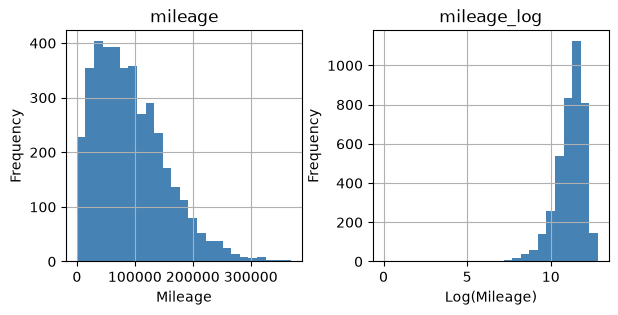

In [51]:
# Log-Transformation of the variable 'mileage'
df_autoscout['mileage_log'] = np.log(df_autoscout['mileage'])       #Kilometerstände logarithmieren und in neuer Spalte speichern
                                                                    #np.log(): natürlichen Logarithmus (Basis e) für jeden Wert berechnen
                                                                    #Voraussetzung: Werte > 0; bei 0 entsteht -inf, bei negativen Werten NaN

# Histogram of the variable 'mileage' and 'mileage_log'
ax = df_autoscout[['mileage', 'mileage_log']].hist(bins=25,                 #Originale und logarithmierte Kilometerstände als zwei Histogramme darstellen
                                                  figsize=(7, 3),           #figsize: Abbildungsgrösse in Zoll (Breite × Höhe)
                                                  color='steelblue')        #hist(): Histogramme erstellen; bins=25: Anzahl Intervalle
                                                                            #color: Balkenfarbe; ax speichert die Diagrammachsen
                                                                            #Erkenntnis: Logarithmierung kann Rechtsschiefe reduzieren und Verteilungsform verändern

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Log(Mileage)']):          #Diagrammachsen und Beschriftungen paarweise durchlaufen
                                                                            #flatten(): Achsenanordnung in 1D umwandeln; zip(): Elemente paarweise verbinden
    axis.set_ylim(bottom=0)                                                 #set_ylim(): y-Achse bei 0 beginnen lassen; Maximum automatisch bestimmen
    axis.set_xlabel(label)                                                  #set_xlabel(): x-Achse mit der jeweiligen Beschriftung versehen
    axis.set_ylabel('Frequency')                                            #set_ylabel(): y-Achse beschriften (Anzahl Fahrzeuge je Intervall)

# Display the plot
plt.show()                                                                  #Beide Histogramme anzeigen

#ANPASSEN: df_autoscout überall durch den verwendeten DataFrame ersetzen (z. B. df_apartments)
#ANPASSEN: mileage überall durch die zu transformierende numerische Spalte ersetzen (z. B. area)
#ANPASSEN: mileage_log überall an den gewünschten Namen der neuen Spalte anpassen
#ANPASSEN: ['Mileage', 'Log(Mileage)'] an die jeweiligen Achsenbeschriftungen anpassen
#OPTIONAL: bins=25, figsize=(7, 3) und color='steelblue' bei Bedarf ändern
#BEI VORGEGEBENER Y-GRENZE: axis.set_ylim(0, 1200) statt axis.set_ylim(bottom=0)
#NICHTS ANPASSEN: np.log(), hist(), flatten(), zip(), set_xlabel(), set_ylabel() und plt.show()
#VORAUSSETZUNG: Numerische Spalte mit ausschliesslich positiven Werten; numpy als np und matplotlib.pyplot als plt importiert

# Weitere

#### Bsp. Veloshop, Gewicht aus Text extrahieren (nicht ausführbar)

In [49]:
import re                                                               #Regex-Funktionen laden

weight = []                                                             #Leere Liste für die extrahierten Zahlen
for i in df['weight_text']:                                             #Jeden Text der Ausgangsspalte durchlaufen
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*kg", i)                       #Zahl vor kg finden: "12,8 kg" ergibt ["12,8"]
    try:                                                                #Ersten Treffer verarbeiten
        d2 = d1[0].strip().replace(',', '.')                            #Ersten Treffer nehmen, Leerraum entfernen und Dezimalkomma ersetzen
    except IndexError:                                                  #Falls kein passender Treffer existiert
        d2 = None                                                       #Fehlenden Wert verwenden
    weight.append(d2)                                                   #Ergebnis an die Liste anhängen

df['weight_kg'] = pd.Series(weight, index=df.index, dtype="float64")    #Als neue Dezimalzahlspalte speichern
df[['weight_text', 'weight_kg']].head()                                 #Ausgangstext und Ergebnis anzeigen

#ANPASSEN: weight_text an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: kg im Regex an die gesuchte Bezeichnung, z. B. Zimmer, m² oder PS
#ANPASSEN: weight_kg an den gewünschten Zielspaltennamen – an beiden Stellen
#NICHTS ANPASSEN: Listenname weight; er muss überall gleich bleiben
#ZAHLENFORMAT: Nichtnegative ganze Zahlen oder Dezimalzahlen mit Komma/Punkt, ohne Tausendertrennzeichen

KeyError: 'weight_text'